# Notebook 04: Classification Modelling — Obesity Prediction

## Objective
This notebook develops and compares machine-learning classification models for predicting obesity among adult NHANES participants.

The target variable is **Obesity**, defined as BMI ≥ 30 kg/m².

Predictors include selected demographic, socioeconomic, lifestyle and clinical characteristics retained from the cleaned analytical dataset. BMI (BMXBMI) and waist circumference (BMXWAIST) are excluded from the predictor set to avoid circular prediction and reliance on an anthropometric measure closely related to BMI-defined obesity.

Classification algorithms are evaluated using the same training and test datasets. Model performance is assessed using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

The analysis also examines model performance and predictor contributions to identify characteristics that provide useful information for obesity classification.

### Step 1. Import Libraries and Load Dataset
The cleaned adult NHANES dataset was loaded and the required libraries for preprocessing, classification modelling and model evaluation were imported.

In [1]:
# 1.1 Import Libraries
# Data manipulation and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and preprocessing
# from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)

from sklearn.calibration import CalibratedClassifierCV

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score, 
    roc_curve,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay,
)

from sklearn.inspection import permutation_importance

# Data splitting and model-selection utilities
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold,
)

In [2]:
# 1.2 Load Dataset
# Load the cleaned analytical dataset
df = pd.read_csv("../outputs/NHANES_Cleaned_Adults.csv")

# Confirm successful loading
print(f"Dataset shape: {df.shape}")
print(f"Number of participants: {len(df):,}")
# Load cleaned analytical dataset
df = pd.read_csv("../outputs/NHANES_Cleaned_Adults.csv")

print("Dataset shape:", df.shape)
print("Participants:", len(df))

Dataset shape: (16943, 48)
Number of participants: 16,943
Dataset shape: (16943, 48)
Participants: 16943


### Step 2. Define Target and Predictors
Obesity was defined as the binary target variables. BMI was excluded from the predictorset because obesity was derived directly from BMI. Waist circumference was also excluded because of its strong relationship with BMI and to avoid reliance on an anthropometric measure closely related to the BMI-defined outcome.

Predictors were divided into continuous and categorical variables to support appropriate preprocessing within the modelling pipelines.

In [3]:
# Define the target variable
target = "Obesity"

# Define continuous predictors
continuous_features = [
    "RIDAGEYR",
    "INDFMPIR",
    "BPXSY1",
    "BPXDI1",
    "LBDHDD",
    "LBXTC",
    "LBXGH",
    "PAD680",
]

# Define categorical predictors
categorical_features = [
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "DMDMARTL",
    "SMQ020",
    "PAQ605",
    "PAQ620",
    "PAQ650",
    "DUQ200",
    "DIQ010",
    "DIQ160",
    "MCQ160A",
    "MCQ160B",
    "MCQ160C",
    "MCQ160E",
    "MCQ160F",
    "DPQ020",
    "WHQ030",
]

# Combine all predictors
predictor_vars = continuous_features + categorical_features

# Create the feature matrix and target vector
X = df[predictor_vars].copy()
y = df[target].copy()

# Summarise the selected variables
print(f"Continuous predictors: {len(continuous_features)}")
print(f"Categorical predictors: {len(categorical_features)}")
print(f"Total predictors: {len(predictor_vars)}")

# Examine the target distribution
print("\nClass distribution:")
print(y.value_counts().sort_index())

print("\nClass percentages:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Continuous predictors: 8
Categorical predictors: 18
Total predictors: 26

Class distribution:
Obesity
0    10309
1     6634
Name: count, dtype: int64

Class percentages:
Obesity
0    60.85
1    39.15
Name: proportion, dtype: float64


The obesity outcome showed a moderate class imbalance, with approximately 61% of participants classified as not obese and 39% as obese. Consequently, classification performance was evaluated using multiple metrics rather than accuracy alone.

### Step 3. Split the Data and Define Preprocessing
The dataset was divided into 80% training and 20% testing subsets using stratification to preserve the obesity class distribution.

Continuous variables were imputed using their training-set medians and standardised.

Categorical variables were imputed using their most frequent categories and one-hot encoded. 

Preprocessing was fitted using training data only to reduce the risk of data leakage.

In [4]:
# Split the data into stratified training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

# Preprocessing for continuous variables
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# Preprocessing for categorical variables
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ]
)

# Combine the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, continuous_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

# Display the dimensions of the resulting subsets
print(f"Training set: {X_train.shape}")
print(f"Testing set: {X_test.shape}")

Training set: (13554, 26)
Testing set: (3389, 26)


### Step 4. Classification Model Comparison
Seven classification algorithms were trained and evaluated using the same stratified training–test split and preprocessing procedure:

- Logistic Regression
- Gaussian Naive Bayes
- Decision Tree
- Random Forest
- Gradient Boosting
- Support Vector Machine (SVM)
- K-Nearest Neighbours (KNN)

Performance was compared using accuracy, precision, recall, F1-score, and ROC–AUC. 

ROC–AUC was used to rank the models because it measures discrimination across classification thresholds.

In [5]:
# Define the classification algorithms
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Naive Bayes": GaussianNB(),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "SVM": CalibratedClassifierCV(
    SVC(random_state=42),
    method="sigmoid",
    cv=5
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

# Initialise containers for results and fitted pipelines
classification_results = []
fitted_models = {}

# Train and evaluate each model
for name, classifier in models.items():

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Train: fit the complete pipeline using the training data
    model.fit(X_train, y_train)

    # Predictions: generate class predictions and predicted probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Store metrics
    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })
    
    # Retain the fitted pipeline for subsequent analyses
    fitted_models[name] = model

# Comparison table: Create and rank the model-comparison table
classification_results = (
    pd.DataFrame(classification_results)
    .sort_values("ROC_AUC", ascending=False)
    .reset_index(drop=True)
)

classification_results.round(4)

classification_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,0.8014,0.7342,0.7724,0.7528,0.8719
1,Gradient Boosting,0.7982,0.7305,0.7679,0.7487,0.8716
2,SVM,0.8035,0.7313,0.7875,0.7583,0.8682
3,Logistic Regression,0.8011,0.7298,0.7815,0.7547,0.8659
4,Naive Bayes,0.7439,0.6631,0.7031,0.6825,0.8142
5,KNN,0.7309,0.6633,0.6353,0.6490,0.7882
6,Decision Tree,0.7170,0.6415,0.6285,0.6349,0.7012


In [6]:
# Save the complete model-comparison results
classification_results.to_csv(
    "../outputs/classification_model_comparison.csv",
    index=False,
)

#### Model Comparison
Seven classification algorithms were evaluated using accuracy, precision, recall, F1-score and ROC-AUC.

Random Forest achieved the highest ROC-AUC (0.8719), indicating the strongest overall ability to discriminate between participants classified as obese and non-obese across classification thresholds. It also achieved the highest precision (0.7342).

SVM achieved the highest accuracy (0.8035), recall (0.7875) and F1-score (0.7583), demonstrating strong overall classification performance and the greatest sensitivity for identifying participants classified as obese.

Gradient Boosting produced a ROC–AUC (0.8716) similarly to that produced by Random Forest (0.8719). 

Logistic Regression also demonstrated strong performance despite its simpler model structure.

Naive Bayes, KNN and Decision Tree produced comparatively weaker results.

Overall, Random Forest and SVM showed strong performance across different evaluation metrics, with Random Forest achieving the highest ROC-AUC and precision and SVM the highest accuracy, recall and F1-score.

### Step 5. Hyperparameter Tuning and Model Selection
Random Forest, Gradient Boosting, SVM and Logistic Regression were selected for hyperparameter tuning because they showed the strongest baseline classification performance.

Random Forest achieved the highest ROC-AUC (0.8719), closely followed by Gradient Boosting (0.8716). SVM achieved the highest accuracy, recall and F1-score, while Logistic Regression also demonstrated strong performance despite its simpler model structure.

RandomizedSearchCV with cross-validation was used to optimise the four models using the training data. ROC-AUC was used as the optimisation metric to provide a consistent criterion across models. The tuned models were subsequently evaluated on the held-out test set using accuracy, precision, recall, F1-score and ROC-AUC.

In [7]:
# Shared cross-validation configuration
# Use the same stratified folds for every model
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)

In [8]:
# Random Forest
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                n_jobs=1,  # Prevent nested parallel processing
            ),
        ),
    ]
)

rf_params = {
    "classifier__n_estimators": [150, 300, 500],
    "classifier__max_depth": [None, 10, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.5],
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=10,
    scoring="roc_auc",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True,
)

rf_search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(rf_search.best_score_, 4))
print("Best parameters:", rf_search.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV ROC-AUC: 0.862
Best parameters: {'classifier__n_estimators': 500, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 30}


In [9]:
# Gradient Boosting
gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            GradientBoostingClassifier(random_state=42),
        ),
    ]
)

gb_params = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__max_depth": [2, 3, 4],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
}

gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_params,
    n_iter=10,
    scoring="roc_auc",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True,
)

gb_search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(gb_search.best_score_, 4))
print("Best parameters:", gb_search.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV ROC-AUC: 0.8639
Best parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.1}


In [10]:
# Support Vector Machine (SVM)
svm_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            SVC(
                kernel="rbf",
                random_state=42,
            ),
        ),
    ]
)

svm_params = {
    "classifier__C": [0.1, 0.5, 1, 5, 10],
    "classifier__gamma": ["scale", 0.01, 0.05, 0.1],
}

svm_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=svm_params,
    n_iter=8,
    scoring="roc_auc",
    cv=cv_strategy,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True,
)

svm_search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(svm_search.best_score_, 4))
print("Best parameters:", svm_search.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV ROC-AUC: 0.8569
Best parameters: {'classifier__gamma': 0.01, 'classifier__C': 0.5}


#### Logistic Regression — Alternative Regularisation Configurations

Two Logistic Regression configurations were explored to examine whether alternative regularisation settings improved cross-validated ROC-AUC.

In [11]:
# Logistic Regression — liblinear configuration
lr_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            LogisticRegression(
                solver="liblinear",
                max_iter=2000,
                random_state=42,
            ),
        ),
    ]
)

lr_params = {
    "classifier__C": [0.01, 0.1, 0.5, 1, 5, 10],
    "classifier__l1_ratio": [0.0, 1.0],
}

lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_params,
    n_iter=8,
    scoring="roc_auc",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True,
)

lr_search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(lr_search.best_score_, 4))
print("Best parameters:", lr_search.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV ROC-AUC: 0.8588
Best parameters: {'classifier__l1_ratio': 1.0, 'classifier__C': 0.5}


In [12]:
# Logistic Regression — L2 regularisation with lbfgs
lr_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            LogisticRegression(
                solver="lbfgs",
                max_iter=1000,
                random_state=42,
            ),
        ),
    ]
)

lr_params = {
    "classifier__C": [0.01, 0.1, 0.5, 1, 5, 10],
}

lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_params,
    n_iter=6,
    scoring="roc_auc",
    cv=cv_strategy,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True,
)

lr_search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(lr_search.best_score_, 4))
print("Best parameters:", lr_search.best_params_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best CV ROC-AUC: 0.8586
Best parameters: {'classifier__C': 0.1}


Two Logistic Regression configurations were explored. Both produced very similar cross-validated ROC-AUC values (0.8588 and 0.8586), indicating that performance was relatively stable across these configurations. The second configuration, using the `lbfgs` solver with L2 regularisation, was retained for subsequent model evaluation.

In [13]:
# Summarise hyperparameter tuning results

tuning_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Gradient Boosting",
        "SVM",
        "Logistic Regression"
    ],
    "Best CV ROC-AUC": [
        rf_search.best_score_,
        gb_search.best_score_,
        svm_search.best_score_,
        lr_search.best_score_
    ],
    "Selected Parameters": [
        rf_search.best_params_,
        gb_search.best_params_,
        svm_search.best_params_,
        lr_search.best_params_
    ]
})

tuning_results = (
    tuning_results
    .sort_values("Best CV ROC-AUC", ascending=False)
    .reset_index(drop=True)
)
# tuning_results


tuning_results.style.format(
    {"Best CV ROC-AUC": "{:.4f}"}
)

,Model,Best CV ROC-AUC,Selected Parameters
0,Gradient Boosting,0.8639,"{'classifier__n_estimators': 200, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.1}"
1,Random Forest,0.8620,"{'classifier__n_estimators': 500, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 30}"
2,Logistic Regression,0.8586,{'classifier__C': 0.1}
3,SVM,0.8569,"{'classifier__gamma': 0.01, 'classifier__C': 0.5}"


In [14]:
# Save the result
tuning_results.to_csv(
    "../outputs/classification_tuning_results.csv",
    index=False
)

#### Cross-Validation Results
Gradient Boosting achieved the highest cross-validated ROC-AUC (0.8641), followed closely by Random Forest (0.8624). Logistic Regression (0.8586) and SVM (0.8576) also showed similar discrimination performance. Overall, the relatively small differences in ROC-AUC indicate that all four selected models performed comparably during cross-validation. The tuned models were subsequently evaluated on the held-out test set to assess their generalisation performance.

In [15]:
# 5.2 Evaluate Tuned Models on the Test Set

tuned_models = {
    "Tuned Random Forest": rf_search.best_estimator_,
    "Tuned Gradient Boosting": gb_search.best_estimator_,
    "Tuned SVM": svm_search.best_estimator_,
    "Tuned Logistic Regression": lr_search.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():

    # Predicted class
    y_pred = model.predict(X_test)

    # Score used for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_score)
    })

tuned_results = pd.DataFrame(tuned_results)

tuned_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Tuned Random Forest,0.8038,0.7348,0.7807,0.7570,0.8726
1,Tuned Gradient Boosting,0.7994,0.7319,0.7694,0.7502,0.8719
2,Tuned SVM,0.7973,0.7041,0.8320,0.7627,0.8663
3,Tuned Logistic Regression,0.7994,0.7277,0.7792,0.7525,0.8655


The tuned models showed similar overall performance on the held-out test set. Random Forest achieved the highest ROC-AUC (0.8726), followed closely by Gradient Boosting (0.8719). SVM achieved the highest recall (0.8320) and F1-score (0.7627), indicating greater sensitivity for identifying participants classified as obese. Differences among the four models were relatively small overall, although the models showed different trade-offs across performance metrics.

In [16]:
# 5.3 Baseline vs Tuned Comparison

selected_models = [
    "Random Forest",
    "Gradient Boosting",
    "SVM",
    "Logistic Regression",
]

# Extract baseline results for the selected models
baseline_selected = classification_results[
    classification_results["Model"].isin(selected_models)
].copy()

baseline_selected["Version"] = "Baseline"

# Prepare tuned results
tuned_selected = tuned_results.copy()
tuned_selected["Model"] = tuned_selected["Model"].str.replace(
    "Tuned ", "",
    regex=False,
)
tuned_selected["Version"] = "Tuned"

# Combine baseline and tuned results
final_comparison = pd.concat(
    [baseline_selected, tuned_selected],
    ignore_index=True,
)

# Arrange models in a consistent order
final_comparison["Model"] = pd.Categorical(
    final_comparison["Model"],
    categories=selected_models,
    ordered=True,
)

final_comparison = (
    final_comparison
    .sort_values(["Model", "Version"])
    .reset_index(drop=True)
)

final_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Version
0,Random Forest,0.8014,0.7342,0.7724,0.7528,0.8719,Baseline
1,Random Forest,0.8038,0.7348,0.7807,0.7570,0.8726,Tuned
2,Gradient Boosting,0.7982,0.7305,0.7679,0.7487,0.8716,Baseline
3,Gradient Boosting,0.7994,0.7319,0.7694,0.7502,0.8719,Tuned
4,SVM,0.8035,0.7313,0.7875,0.7583,0.8682,Baseline
5,SVM,0.7973,0.7041,0.8320,0.7627,0.8663,Tuned
6,Logistic Regression,0.8011,0.7298,0.7815,0.7547,0.8659,Baseline
7,Logistic Regression,0.7994,0.7277,0.7792,0.7525,0.8655,Tuned


In [17]:
# Save comparison table
final_comparison.to_csv(
    "../outputs/classification_tuning_comparison.csv",
    index=False
)

In [18]:
# Calculate the change in each metric after tuning
metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
]

comparison_wide = final_comparison.pivot(
    index="Model",
    columns="Version",
    values=metric_columns,
)

metric_changes = pd.DataFrame(index=comparison_wide.index)

for metric in metric_columns:
    metric_changes[f"{metric}_Change"] = (
        comparison_wide[(metric, "Tuned")]
        - comparison_wide[(metric, "Baseline")]
    )

metric_changes.reset_index().round(4)

,Model,Accuracy_Change,Precision_Change,Recall_Change,F1_Change,ROC_AUC_Change
0,Random Forest,0.0024,0.0005,0.0083,0.0042,0.0007
1,Gradient Boosting,0.0012,0.0014,0.0015,0.0015,0.0003
2,SVM,-0.0062,-0.0272,0.0445,0.0043,-0.0020
3,Logistic Regression,-0.0018,-0.0021,-0.0023,-0.0022,-0.0004


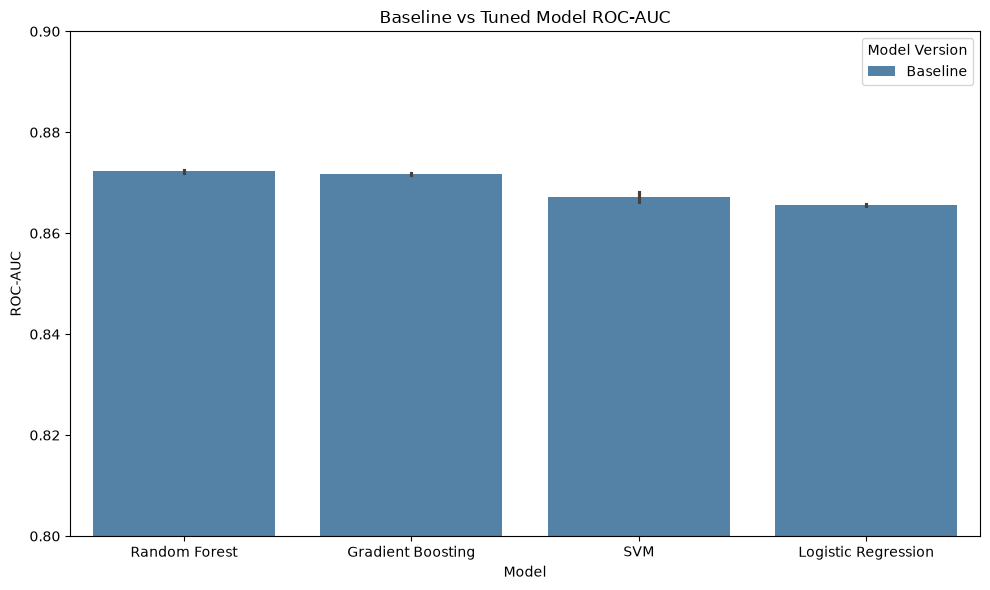

In [19]:
# Plot baseline versus tuned ROC-AUC

# Prepare data for plotting
plot_comparison = final_comparison.copy()

plot_comparison["Tuning"] = plot_comparison["Model"].apply(
    lambda x: "Tuned" if x.startswith("Tuned") else "Baseline"
)

plot_comparison["Model"] = (
    plot_comparison["Model"]
    .str.replace("Baseline ", "", regex=False)
    .str.replace("Tuned ", "", regex=False)
)

# Plot baseline vs tuned ROC-AUC
plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_comparison,
    x="Model",
    y="ROC_AUC",
    hue="Tuning",
    palette={
        "Baseline": "steelblue",
        "Tuned": "darkorange"
    }
)

plt.title("Baseline vs Tuned Model ROC-AUC")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.ylim(0.80, 0.90)
plt.legend(title="Model Version")
plt.tight_layout()
plt.show()

#### Hyperparameter Tuning Interpretation
Hyperparameter tuning produced only small changes in held-out test-set performance across the four selected models. 

Random Forest and Gradient Boosting showed small increases in ROC-AUC after tuning, whereas SVM and Logistic Regression showed slight decreases.

Logistic Regression also showed little change in overall discrimination.

The tuned SVM achieved higher recall than its baseline counterpart but showed slightly lower accuracy, precision and ROC-AUC, illustrating a trade-off between sensitivity and other performance measures. 

Overall, hyperparameter tuning did not produce a substantial improvement in generalisation performance, indicating that the baseline models were already performing close to the tuned configurations.

### Step 6. Final Baseline Model Comparison
Hyperparameter tuning produced no meaningful improvement in held-out test performance. The baseline Random Forest, Gradient Boosting, SVM, and Logistic Regression models were therefore retained for the final comparison.

ROC curves were used to compare the models’ ability to discriminate between participants classified as obese and those classified as not obese across all classification thresholds.

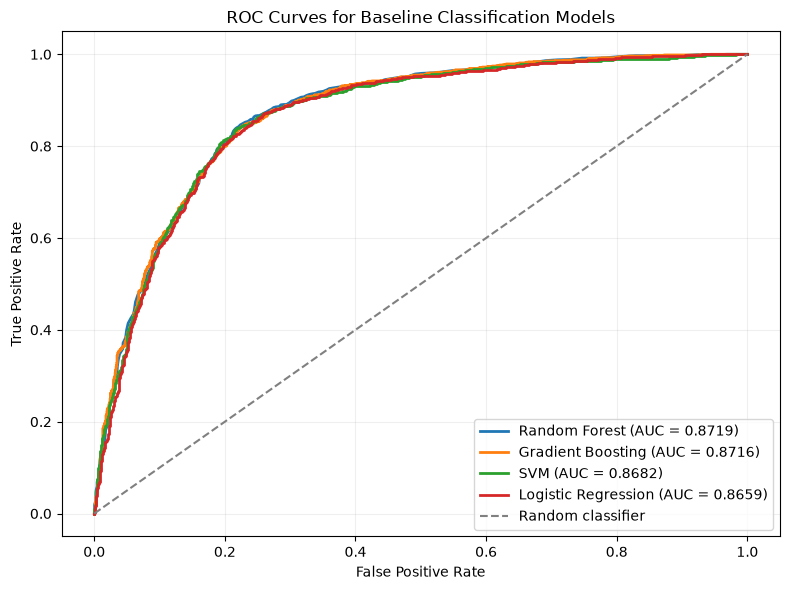

In [20]:
# 6. Final Baseline Model Comparison

# Retrieve the fitted baseline models
final_models = {
    "Random Forest": fitted_models["Random Forest"],
    "Gradient Boosting": fitted_models["Gradient Boosting"],
    "SVM": fitted_models["SVM"],
    "Logistic Regression": fitted_models["Logistic Regression"],
}

# Create the ROC-curve figure
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in final_models.items():
    # Obtain continuous prediction scores
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # Calculate ROC curve and ROC-AUC
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)

    # Plot with ROC-AUC displayed to four decimal places
    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.4f})",
    )

# Add the random-classifier reference line
ax.plot(
    [0, 1],
    [0, 1],
    color="grey",
    linestyle="--",
    linewidth=1.5,
    label="Random classifier",
)

ax.set_title("ROC Curves for Baseline Classification Models")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

All four ROC curves were well above the random-classifier reference line, demonstrating good discrimination between participants classified as obese and those classified as not obese. 

Random Forest achieved the highest baseline ROC–AUC (0.8719), closely followed by Gradient Boosting (0.8716), SVM (0.8682), and Logistic Regression (0.8659). The substantial overlap among the ROC curves reflects the small differences in discrimination performance. 

Random Forest was retained as the leading baseline model according to ROC–AUC, although the results indicate that all four models performed comparably.

### Step 7. Confusion Matrices

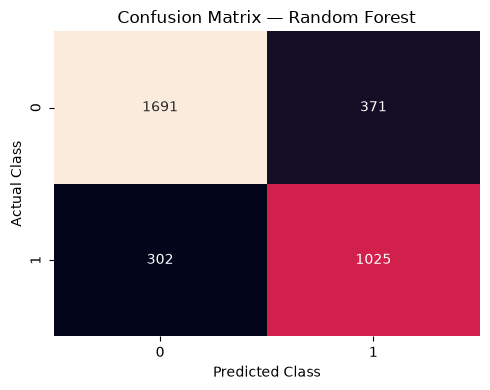

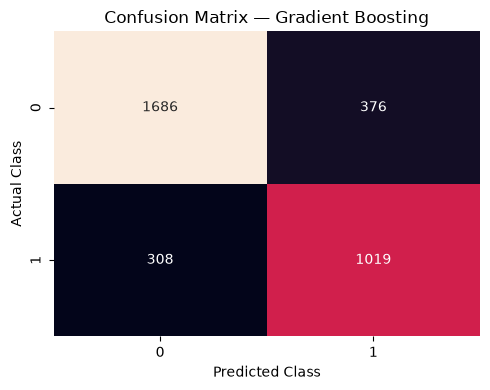

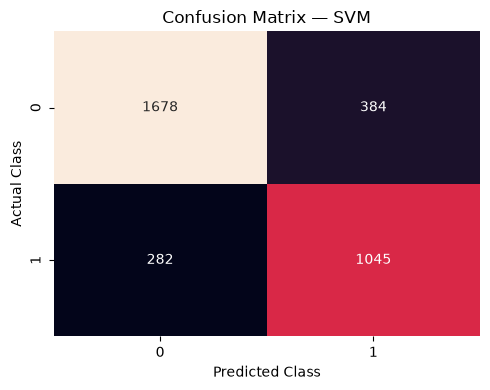

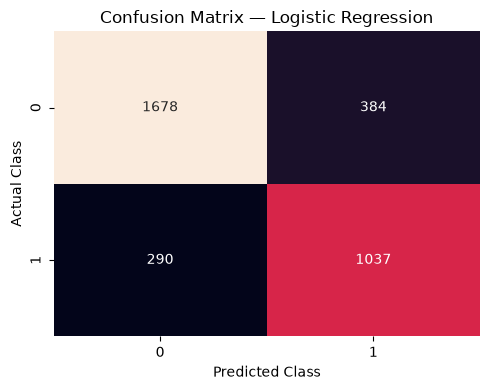

In [21]:
for name, model in final_models.items():

    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cbar=False
    )

    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()
    plt.show()

In [22]:
# Classification Reports

for name, model in final_models.items():

    y_pred = model.predict(X_test)

    print(f"\n{name} Classification Report")
    print("-" * 45)
    print(classification_report(y_test, y_pred))


Random Forest Classification Report
---------------------------------------------
              precision    recall  f1-score   support

           0       0.85      0.82      0.83      2062
           1       0.73      0.77      0.75      1327

    accuracy                           0.80      3389
   macro avg       0.79      0.80      0.79      3389
weighted avg       0.80      0.80      0.80      3389


Gradient Boosting Classification Report
---------------------------------------------
              precision    recall  f1-score   support

           0       0.85      0.82      0.83      2062
           1       0.73      0.77      0.75      1327

    accuracy                           0.80      3389
   macro avg       0.79      0.79      0.79      3389
weighted avg       0.80      0.80      0.80      3389


SVM Classification Report
---------------------------------------------
              precision    recall  f1-score   support

           0       0.86      0.81      0.83     

Seven classification algorithms were evaluated for predicting BMI-defined obesity using demographic, socioeconomic, lifestyle and clinical characteristics, with BMI and waist circumference excluded from the predictor set.

Among the baseline models, Random Forest achieved the highest ROC-AUC (0.8719), closely followed by Gradient Boosting (0.8716), indicating strong discrimination between participants classified as obese and non-obese across classification thresholds. SVM achieved the highest accuracy (0.8035), recall (0.7875) and F1-score (0.7583), while Logistic Regression also demonstrated competitive performance.

Hyperparameter tuning of Random Forest, Gradient Boosting, SVM and Logistic Regression produced only small changes in held-out test performance and did not provide a substantial overall improvement over the baseline models. The baseline models were therefore retained for final comparison.

Overall, the results demonstrate that several modelling approaches achieved similar classification performance. Random Forest provided the highest overall discrimination, whereas SVM showed greater sensitivity for identifying participants classified as obese. These differences highlight the importance of considering multiple evaluation metrics rather than selecting a model based on a single performance measure.

### Step 8. Predictor Interpretation

#### 8.1 Random Forest Feature Importance
Random Forest feature importance was examined to identify the predictors that contributed most strongly to obesity classification. Because categorical predictors were one-hot encoded during preprocessing, importance was first calculated for the transformed features and then examined across the resulting predictor categories.

Random Forest impurity-based feature importance was used as a descriptive measure of predictive contribution. Because this measure may favour variables offering more potential splits, the resulting rankings were interpreted cautiously. Feature importance reflects a variable's contribution to prediction within the fitted model and should not be interpreted as evidence of a causal relationship with obesity.

In [23]:
# 8.1 Random Forest Feature Importance

# Retrieve fitted Random Forest pipeline
rf_model = fitted_models["Random Forest"]

# Retrieve fitted preprocessor and classifier
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

# Get transformed feature names
feature_names = rf_preprocessor.get_feature_names_out()

# Extract feature importances
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

# Sort from highest to lowest importance
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

feature_labels = {
    "cat__WHQ030_1.0": "Wants to lose weight",
    "cat__WHQ030_3.0": "Wants to maintain weight",
    "cat__WHQ030_2.0": "Wants to gain weight",

    "num__LBDHDD": "HDL cholesterol",
    "num__LBXGH": "HbA1c",
    "num__LBXTC": "Total cholesterol",
    "num__BPXSY1": "Systolic blood pressure",
    "num__RIDAGEYR": "Age",
    "num__INDFMPIR": "Income-to-poverty ratio",
    "num__BPXDI1": "Diastolic blood pressure",
    "num__PAD680": "Sedentary time",

    "cat__RIDRETH3_6.0": "Non-Hispanic Asian",
    "cat__RIDRETH3_4.0": "Non-Hispanic Black",
    "cat__RIDRETH3_3.0": "Non-Hispanic White",

    "cat__DMDMARTL_1.0": "Married",
    "cat__DMDEDUC2_4.0": "Some college/associate degree",
    "cat__DMDEDUC2_5.0": "College graduate or above",

    "cat__SMQ020_2.0": "Never smoked 100 cigarettes",
    "cat__SMQ020_1.0": "Smoked at least 100 cigarettes",

    "cat__RIAGENDR_1.0": "Male"
}

# Add readable feature labels
feature_importance["Feature_Label"] = (
    feature_importance["Feature"]
    .map(feature_labels)
    .fillna(feature_importance["Feature"])
)

# Display top 20 predictors
feature_importance[
    ["Feature_Label", "Importance"]
].head(20)

# Display top 20 predictors
# feature_importance.head(20)

,Feature_Label,Importance
0,Wants to lose weight,0.148903
1,Wants to maintain weight,0.097048
2,HDL cholesterol,0.071620
3,HbA1c,0.057605
4,Total cholesterol,0.056534
5,Systolic blood pressure,0.056532
6,Age,0.056231
7,Income-to-poverty ratio,0.051498
8,Diastolic blood pressure,0.047585
9,Sedentary time,0.042287


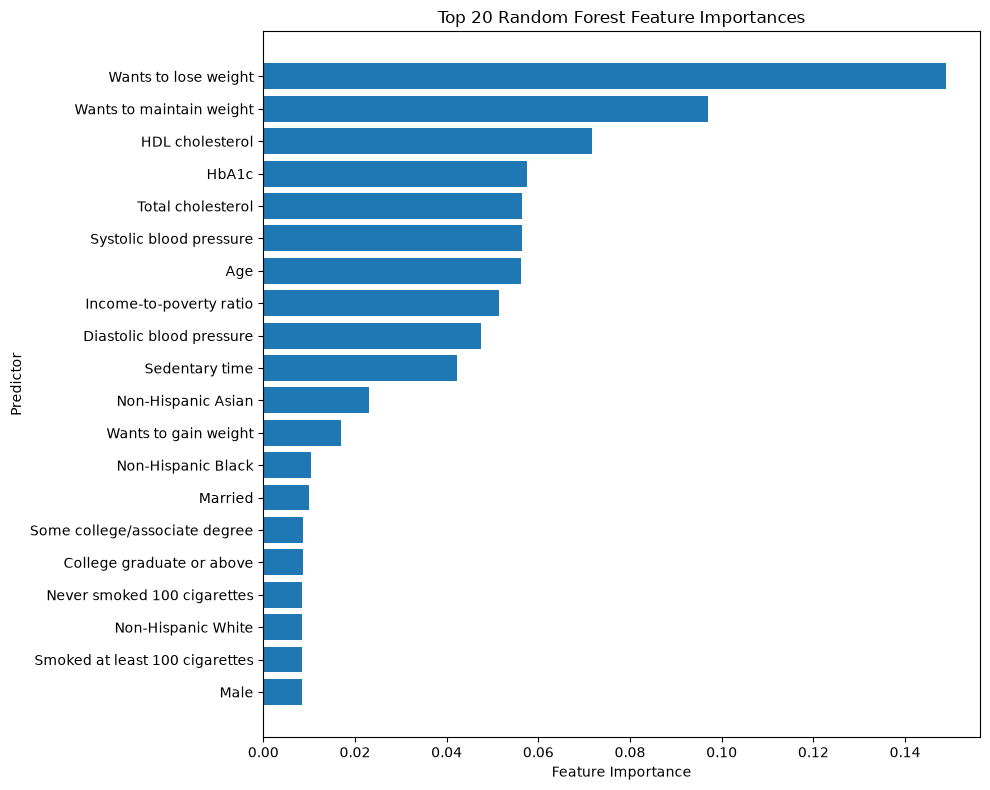

In [24]:
# Plot top 20 Random Forest feature importances

top_features = feature_importance.head(20).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature_Label"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Predictor")
plt.title("Top 20 Random Forest Feature Importances")

plt.tight_layout()
plt.show()

#### 8.2 Aggregate Importance by Original Predictor
To improve interpretability, importance values for one-hot encoded categories were mapped back to their original predictors and summed to obtain an aggregated importance value for each original variable.

In [25]:
# Map transformed features back to original predictors

def get_original_feature(transformed_feature):

    # Continuous variables
    if transformed_feature.startswith("num__"):
        return transformed_feature.replace("num__", "")

    # Categorical variables
    if transformed_feature.startswith("cat__"):
        feature = transformed_feature.replace("cat__", "")

        for variable in categorical_features:
            if feature.startswith(variable + "_"):
                return variable

    return transformed_feature


feature_importance["Original_Feature"] = (
    feature_importance["Feature"].apply(get_original_feature)
)

original_feature_labels = {
    "WHQ030": "Weight-change intention",
    "LBDHDD": "HDL cholesterol",
    "RIDRETH3": "Race/ethnicity",
    "LBXGH": "HbA1c",
    "LBXTC": "Total cholesterol",
    "BPXSY1": "Systolic blood pressure",
    "RIDAGEYR": "Age",
    "INDFMPIR": "Income-to-poverty ratio",
    "BPXDI1": "Diastolic blood pressure",
    "PAD680": "Sedentary time",
    "DMDEDUC2": "Education",
    "DMDMARTL": "Marital status",
    "DPQ020": "Feeling depressed or hopeless",
    "SMQ020": "Smoking history",
    "RIAGENDR": "Sex",
    "PAQ620": "Moderate recreational activity",
    "DIQ010": "Diabetes status",
    "DUQ200": "Marijuana use history",
    "MCQ160A": "Arthritis status",
    "PAQ605": "Vigorous work activity",
    "PAQ650": "Vigorous recreational activity",
    "DIQ160": "Prediabetes status",
    "MCQ160F": "Stroke history",
    "MCQ160E": "Heart attack history",
    "MCQ160B": "Congestive heart failure history",
    "MCQ160C": "Coronary heart disease history"
}

# Sum importance across one-hot encoded categories
aggregated_importance = (
    feature_importance
    .groupby("Original_Feature", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Add descriptive labels
aggregated_importance["Feature_Label"] = (
    aggregated_importance["Original_Feature"]
    .map(original_feature_labels)
    .fillna(aggregated_importance["Original_Feature"])
)

display(
    aggregated_importance[
        ["Feature_Label", "Importance"]
    ]
)

,Feature_Label,Importance
0,Weight-change intention,0.263000
1,HDL cholesterol,0.071620
2,Race/ethnicity,0.058288
3,HbA1c,0.057605
4,Total cholesterol,0.056534
5,Systolic blood pressure,0.056532
6,Age,0.056231
7,Income-to-poverty ratio,0.051498
8,Diastolic blood pressure,0.047585
9,Sedentary time,0.042287


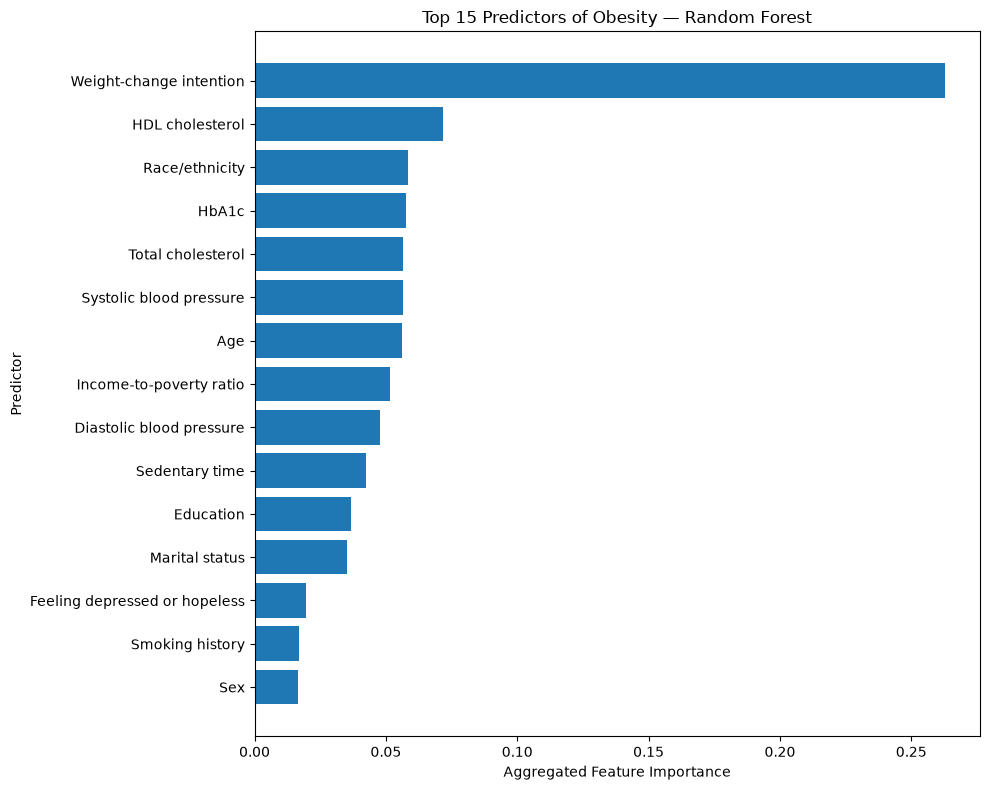

In [26]:
# Plot aggregated Random Forest feature importance

top_predictors = (
    aggregated_importance
    .head(15)
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_predictors["Feature_Label"],
    top_predictors["Importance"]
)

plt.xlabel("Aggregated Feature Importance")
plt.ylabel("Predictor")
plt.title("Top 15 Predictors of Obesity — Random Forest")

plt.tight_layout()
plt.show()

#### Predictor Importance Interpretation
Weight-change intention (WHQ030) had the highest aggregated Random Forest feature importance (0.2630), substantially exceeding that of any other individual predictor. This finding should be interpreted cautiously because weight-change intention may reflect an individual's existing weight status and therefore may contain information arising after, or in response to, excess body weight.

Beyond weight-change intention, predictive information was distributed across several domains. Among the more influential predictors were HDL cholesterol (LBDHDD), race/ethnicity (RIDRETH3), HbA1c (LBXGH), total cholesterol (LBXTC), systolic blood pressure (BPXSY1), age (RIDAGEYR), income-to-poverty ratio (INDFMPIR), diastolic blood pressure (BPXDI1) and sedentary time (PAD680). Education and marital status also contributed predictive information.

These importance values describe contributions to prediction within the fitted Random Forest and do not indicate the direction of associations or establish causal relationships with obesity.

#### 8.3 Permutation Importance
Permutation importance was used as an additional model-interpretation method to assess how much Random Forest performance decreased when the values of each predictor were randomly permuted in the held-out test set. ROC-AUC was used as the scoring metric. Unlike the impurity-based analysis, permutation importance was calculated for the original predictor variables before one-hot encoding.

In [27]:
# 8.3 Permutation Importance

# Retrieve fitted baseline Random Forest
rf_final = fitted_models["Random Forest"]

permutation_result = permutation_importance(
    rf_final,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

permutation_df = pd.DataFrame({
    "Predictor": X_test.columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_SD": permutation_result.importances_std
})

permutation_df = (
    permutation_df
    .sort_values("Importance_Mean", ascending=False)
    .reset_index(drop=True)
)

original_feature_labels = {
    "WHQ030": "Weight-change intention",
    "LBDHDD": "HDL cholesterol",
    "RIDRETH3": "Race/ethnicity",
    "LBXGH": "HbA1c",
    "LBXTC": "Total cholesterol",
    "BPXSY1": "Systolic blood pressure",
    "RIDAGEYR": "Age",
    "INDFMPIR": "Income-to-poverty ratio",
    "BPXDI1": "Diastolic blood pressure",
    "PAD680": "Sedentary time",
    "DMDEDUC2": "Education",
    "DMDMARTL": "Marital status",
    "DPQ020": "Feeling depressed or hopeless",
    "SMQ020": "Smoking history",
    "RIAGENDR": "Sex",
    "PAQ620": "Moderate recreational activity",
    "DIQ010": "Diabetes status",
    "DUQ200": "Marijuana use history",
    "MCQ160A": "Arthritis status",
    "PAQ605": "Vigorous work activity",
    "PAQ650": "Vigorous recreational activity",
    "DIQ160": "Prediabetes status",
    "MCQ160F": "Stroke history",
    "MCQ160E": "Heart attack history",
    "MCQ160B": "Congestive heart failure history",
    "MCQ160C": "Coronary heart disease history"
}

# Add descriptive predictor names
permutation_df["Feature_Label"] = (
    permutation_df["Predictor"]
    .map(original_feature_labels)
    .fillna(permutation_df["Predictor"])
)

display(
    permutation_df[
        ["Feature_Label", "Importance_Mean", "Importance_SD"]
    ].round(4)
)

,Feature_Label,Importance_Mean,Importance_SD
0,Weight-change intention,0.2377,0.0041
1,Race/ethnicity,0.0308,0.0023
2,HDL cholesterol,0.0117,0.0009
3,HbA1c,0.0093,0.0019
4,Systolic blood pressure,0.0057,0.0011
5,Age,0.0052,0.0008
6,Education,0.0041,0.0005
7,Sex,0.0029,0.0005
8,Arthritis status,0.0028,0.0008
9,Diabetes status,0.0028,0.0008


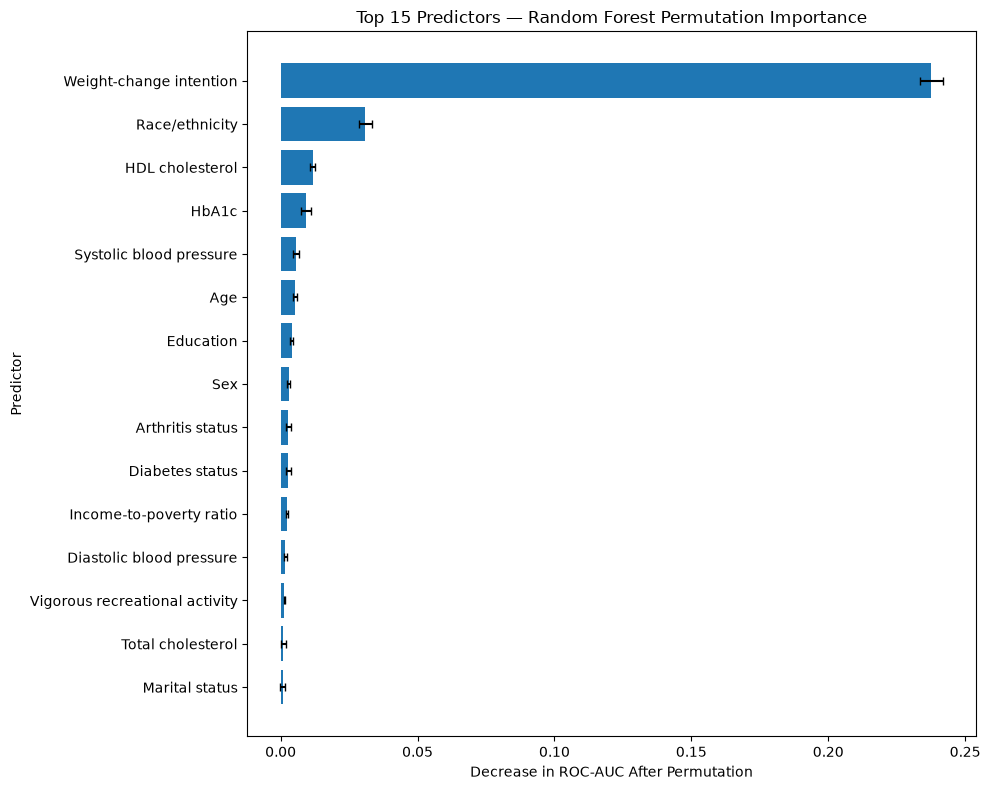

In [28]:
# Plot top 15 permutation importances

top_permutation = (
    permutation_df
    .head(15)
    .sort_values("Importance_Mean", ascending=True)
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_permutation["Feature_Label"],
    top_permutation["Importance_Mean"],
    xerr=top_permutation["Importance_SD"],
    capsize=3
)

plt.xlabel("Decrease in ROC-AUC After Permutation")
plt.ylabel("Predictor")
plt.title("Top 15 Predictors — Random Forest Permutation Importance")

plt.tight_layout()
plt.show()

Permutation importance confirmed that weight-change intention (WHQ030) was the dominant predictor in the Random Forest model. Permuting WHQ030 reduced test-set ROC-AUC by approximately 0.2377, substantially more than any other predictor. Race/ethnicity (RIDRETH3) produced the second-largest reduction in ROC-AUC (0.0308), followed by HDL cholesterol (LBDHDD; 0.0117) and HbA1c (LBXGH; 0.0093).

Smaller decreases in ROC-AUC were observed after permuting systolic blood pressure (BPXSY1), age (RIDAGEYR), education (DMDEDUC2), sex (RIAGENDR), arthritis status (MCQ160A), diabetes status (DIQ010) and income-to-poverty ratio (INDFMPIR). Several other predictors produced little change in test-set ROC-AUC when permuted individually.

The strong importance of WHQ030 was consistent with the impurity-based feature-importance analysis. However, this finding should be interpreted cautiously because weight-change intention may reflect existing weight status rather than represent an antecedent risk factor for obesity. Permutation importance measures predictive contribution, not causality or the direction of an association.

#### 8.4 Predictor Interpretation Summary
Both impurity-based and permutation importance identified weight-change intention (WHQ030) as the dominant predictor of BMI-defined obesity in the Random Forest model.

Race/ethnicity, HDL cholesterol, HbA1c, blood pressure, age and selected socioeconomic and clinical characteristics also contributed predictive information, although their relative importance differed between the two methods.

The differences between the importance methods highlight that predictor rankings depend partly on how importance is measured. Overall, the findings indicate that obesity classification was informed by characteristics spanning behavioural, demographic, clinical and socioeconomic domains, while the particularly strong contribution of weight-change intention requires cautious interpretation because it may partly reflect participants' existing awareness of or response to their weight status.

### Step 9. Save Final Outputs
The final model-comparison and predictor-importance tables were saved for reporting and reproducibility.

In [29]:
# Save baseline model comparison
classification_results.to_csv(
    "../outputs/classification_model_comparison.csv",
    index=False
)

# Save hyperparameter tuning results
tuning_results.to_csv(
    "../outputs/classification_tuning_results.csv",
    index=False
)

# Save baseline vs tuned comparison
final_comparison.to_csv(
    "../outputs/classification_tuning_comparison.csv",
    index=False
)

# Save aggregated Random Forest feature importance
aggregated_importance.to_csv(
    "../outputs/random_forest_feature_importance.csv",
    index=False
)

# Save permutation importance
permutation_df.to_csv(
    "../outputs/random_forest_permutation_importance.csv",
    index=False
)

print("Final analysis outputs saved successfully.")

Final analysis outputs saved successfully.
